# Tahap 15 — Analisis tambahan E0/E1: prediksi dan attention map

**Status: tambahan eksploratori, dirancang setelah hasil S3/S5 diketahui.**
Notebook ini tidak mengubah preregistrasi atau keputusan analisis lama. Ia membaca
artefak yang sudah ada, berjalan di CPU, dan tidak memuat model, melakukan tuning,
training, inferensi baru, SHAP baru, atau perubahan manuskrip.

- **E0:** probabilitas per rekaman → mean probabilitas per subjek → AUROC per
  seed → mean AUROC antar-seed. Bootstrap subjek mempertahankan seluruh keluaran
  model/seed yang berpasangan dalam setiap kohort; kedua kohort di-bootstrap independen.
- **E1:** perubahan probabilitas, logit, dan attention pada rekaman yang sama antar-seed,
  memakai logit dan peta yang tersimpan bersama pada artefak NewHandPD.

CI bersyarat pada model OOF, split, konfigurasi, dan seed yang tersedia. Resampling
subjek tidak melatih ulang fold yang saling bergantung. Hasil tidak menguji ketahanan
satu model beku pada kohort baru. **Perubahan peta bukan bukti hilangnya faithfulness;
faithfulness langsung tetap pertanyaan E2.**

Pilih kernel **Skripsi (.venv)**, lalu **Restart Kernel and Run All** agar modul
yang dimuat sesuai dengan snapshot sumber. Detail tersedia di
`scripts/E0-E1.md`. Keluaran baru masuk subdirektori bertimestamp; hasil lama tidak ditimpa.


In [1]:
from pathlib import Path
import sys, json, platform
from datetime import datetime, timezone
from importlib.metadata import version

def cari_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "src/audit_e0_e1.py").exists() and (path / "results").is_dir():
            return path
    raise FileNotFoundError("jalankan notebook dari root proyek atau notebooks/")

ROOT = cari_root()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from audit_e0_e1 import (
    STATUS_ANALISIS, BATAS_INFERENSI, E1_METRICS, file_sha256, cache_manifest,
    prepare_cohort, subject_scores, reference_check, e0_bootstrap, e1_pairs,
    e1_subject_summary, e1_subject_relations, e1_sensitivity, bootstrap_subject_table,
)
from viz import WARNA, pasang_gaya, rapikan
pasang_gaya()
print("Root:", ROOT)
print("Status:", STATUS_ANALISIS)
print("Batas:", BATAS_INFERENSI)

Root: /home/agribychaniago/Python Projects/Skripsi
Status: tambahan_eksploratori_setelah_hasil_S3_S5_diketahui
Batas: Bersyarat pada artefak model OOF, split, konfigurasi dan seed yang tersedia; tidak mencakup training ulang, split baru, kohort baru, atau faithfulness.


## 1. Pilihan analisis tambahan

BiGRU dan BiMamba-2 adalah perbandingan utama tambahan. Daftar seed **eksplisit**,
bukan irisan seed yang kebetulan tersedia. Run atau peta yang hilang menyebabkan
analisis berhenti. Tidak ada imputasi seed lama menjadi 0.

Ambang probabilitas/logit hanya analisis sensitivitas. Semua pasangan tetap dipakai
untuk ringkasan kontinu. Ambang kelas memakai logit 0 (probabilitas 0,5), sebagai
kesepakatan keputusan model, bukan ambang diagnostik yang telah divalidasi.


In [2]:
ARMS = ("gru", "mamba2")
SEEDS = tuple(range(10))
PATCH = 7
FS = 100.0
EXPECTED_CONFIG = {
    "patch_size": PATCH, "epochs": 35, "in_channels": 6,
    "d_model": 128, "n_layers": 3, "dropout": 0.30, "pooling": "attention",
}
N_BOOT = 5000
BOOT_SEED_E0 = 1500
BOOT_SEED_E1 = 1501
CONFIDENCE = 0.95
TOP_FRACTION = 0.10
EPS_PROB = (0.01, 0.02, 0.05)
EPS_LOGIT = (None, 0.10, 0.25, 0.50)

# Referensi 4 desimal yang telah dilaporkan, bukan hasil baru notebook ini.
HEADLINES = {
    "uci395": {"gru": 0.9503, "mamba2": 0.9338},
    "newhandpd": {"gru": 0.8959, "mamba2": 0.9307},
}
INPUTS = {
    "uci_artifact": ROOT / "results/s3_artefak.pkl",
    "new_artifact": ROOT / "results/s5_artefak.pkl",
    "uci_cache": ROOT / "data/cache/uci395_fs100.npz",
    "new_cache": ROOT / "data/cache/newhandpd_spiral_fs100.npz",
    "uci_reference": ROOT / "results/s3_per_seed.csv",
    "new_reference": ROOT / "results/s5_per_seed.csv",
    "frozen_parameters": ROOT / "results/s2_parameter_dibekukan.csv",
}
SOURCE_FILES = [ROOT / p for p in (
    "src/audit_e0_e1.py", "scripts/build_nb_15.py",
    "scripts/build_nb_07.py", "scripts/build_nb_12.py",
    "notebooks/07_eksperimen_utama.ipynb", "notebooks/12_replikasi_newhandpd.ipynb",
    "src/preprocessing.py", "src/newhandpd.py", "src/model.py", "src/training.py",
)]
for path in [*INPUTS.values(), *SOURCE_FILES]:
    if not path.is_file():
        raise FileNotFoundError(f"input wajib tidak tersedia: {path}; tidak dibuat/dilatih otomatis")
frozen = pd.read_csv(INPUTS["frozen_parameters"])
if int(frozen.patch_halus.iloc[0]) != PATCH or int(frozen.epoch_dibekukan.iloc[0]) != EXPECTED_CONFIG["epochs"]:
    raise ValueError("PATCH/epochs audit berbeda dari metadata parameter beku")
inventory = pd.DataFrame([
    {"path": str(p.relative_to(ROOT)), "sha256_before": file_sha256(p), "bytes": p.stat().st_size}
    for p in [*INPUTS.values(), *SOURCE_FILES]
])
display(inventory[["path", "bytes", "sha256_before"]])

,path,bytes,sha256_before
0,results/s3_artefak.pkl,61546,efd92ef1c9639e3b4443aa6c3dfaf9b9d758177208c90d...
1,results/s5_artefak.pkl,41745069,f46387be88b7b05d0ea3941514efc9602cf7ca931bd8b8...
2,data/cache/uci395_fs100.npz,13361739,b82e56a86da170c68bd7b32fc93d32ec23b00b7116cce7...
3,data/cache/newhandpd_spiral_fs100.npz,15450419,d69fc2c049ce7bb8ffab12dc6f17aed4452c3bf6bdc64f...
4,results/s3_per_seed.csv,1977,5939fda6502dd5a362c31c166ca5c5d87e2046c1cd9b04...
5,results/s5_per_seed.csv,826,cb648dc40ed0e5558f2f5770c4a5a3075e4a792a0dc373...
6,results/s2_parameter_dibekukan.csv,289,68b875abb1e3989462d7782ae7898bc1b74ca2dd39c30e...
7,src/audit_e0_e1.py,33170,f737d1ddaf57be8b9d33301b5f1b190df747eb33ea4207...
8,scripts/build_nb_15.py,24415,2e2994646276ef4cfd147fc666ad6e08bbf07ff7f61975...
9,scripts/build_nb_07.py,19242,0b2ff340c614fcc0491bafceedca2acd7335993382a212...


## 2. Pemeriksaan identitas dan batas provenans

Pemeriksaan keras: seed/run unik dan lengkap; panjang logit sesuai cache; identitas
rekaman `(subjek, task, segmen)` unik; label konsisten; setiap peta S5 cocok dengan
`idx`, subjek dan label; panjang peta tepat `floor(T/7)`; α finite/nonnegatif dengan
massa 1. Tidak ada crop, interpolasi, pergeseran peta, atau irisan rekaman diam-diam.
Patch j dimulai pada `j*0,07` detik dan berakhir pada `(j+1)*0,07` detik. Sisa sampel
di luar patch penuh dicatat dalam `tail_samples`.

**Batas artefak lama:** fold historis, konfigurasi lengkap, hash cache saat training,
dan model/checkpoint ID tidak tersedia. Fold direkonstruksi dengan SGKF5,
`shuffle=True, random_state=42` pada urutan cache saat audit. Ini hanya rekonstruksi.
Konfigurasi di atas adalah ekspektasi dari kode, bukan metadata training yang ditemukan.
Hash baru mencatat keadaan saat audit; ia tidak membuktikan identitas berkas lama.
Logit/peta S5 berada dalam entri run yang sama, tetapi bobot historis tidak dapat
diautentikasi. Laporan mempertahankan perbedaan status tersebut.


In [3]:
records_uci = cache_manifest(INPUTS["uci_cache"], "uci395", PATCH, FS)
records_new = cache_manifest(INPUTS["new_cache"], "newhandpd", PATCH, FS)
uci = prepare_cohort(INPUTS["uci_artifact"], records_uci, ARMS, SEEDS, EXPECTED_CONFIG)
new = prepare_cohort(INPUTS["new_artifact"], records_new, ARMS, SEEDS,
                     EXPECTED_CONFIG, require_maps=True)
checks = pd.concat([uci.checks, new.checks], ignore_index=True)
display(checks.groupby(["cohort", "field", "status"]).size().rename("n_run").reset_index())
display(new.records[["idx", "record_id", "subject", "label", "task", "fold_reconstructed",
                     "n_samples", "n_patches", "tail_samples", "patch_seconds"]].head(12))
print("Pemeriksaan keselarasan lulus. Metadata berstatus tidak_tersimpan/rekonstruksi tetap belum terverifikasi.")

,cohort,field,status,n_run
0,newhandpd,config.d_model,tidak_tersimpan,20
1,newhandpd,config.dropout,tidak_tersimpan,20
2,newhandpd,config.epochs,tidak_tersimpan,20
3,newhandpd,config.in_channels,tidak_tersimpan,20
4,newhandpd,config.n_layers,tidak_tersimpan,20
5,newhandpd,config.patch_size,tidak_tersimpan,20
6,newhandpd,config.pooling,tidak_tersimpan,20
7,newhandpd,fold,rekonstruksi_bukan_bukti_historis,20
8,newhandpd,idx_subjek_label_grid,terverifikasi,20
9,newhandpd,model_id_cache_training,tidak_tersimpan,20


,idx,record_id,subject,label,task,fold_reconstructed,n_samples,n_patches,tail_samples,patch_seconds
0,0,newhandpd:H1:task0:seg0,H1,0,0,1,1070,152,6,0.07
1,1,newhandpd:H10:task0:seg0,H10,0,0,1,1180,168,4,0.07
2,2,newhandpd:H11:task0:seg0,H11,0,0,3,1290,184,2,0.07
3,3,newhandpd:H12:task0:seg0,H12,0,0,4,1460,208,4,0.07
4,4,newhandpd:H13:task0:seg0,H13,0,0,4,1290,184,2,0.07
5,5,newhandpd:H14:task0:seg0,H14,0,0,4,800,114,2,0.07
6,6,newhandpd:H16:task0:seg0,H16,0,0,1,870,124,2,0.07
7,7,newhandpd:H17:task0:seg0,H17,0,0,3,1450,207,1,0.07
8,8,newhandpd:H18:task0:seg0,H18,0,0,3,720,102,6,0.07
9,9,newhandpd:H19:task0:seg0,H19,0,0,1,2080,297,1,0.07


Pemeriksaan keselarasan lulus. Metadata berstatus tidak_tersimpan/rekonstruksi tetap belum terverifikasi.


## 3. E0 — cocokkan estimator dengan angka headline sebelum bootstrap

Probabilitas diambil dari sigmoid logit setiap rekaman. Probabilitas **dirata-ratakan
per subjek untuk setiap seed**, lalu AUROC dihitung per seed. Tidak ada mean logit,
dan tidak ada penghitungan AUROC pada probabilitas ensemble.

Referensi per-seed S3/S5 harus cocok pada toleransi numerik 1e-8. Mean AUROC per-seed
juga harus cocok dengan headline yang dibulatkan empat desimal. Ketidakcocokan
menghentikan analisis agar estimator/data yang berbeda tidak dianggap mengonfirmasi headline.


In [4]:
scores = {"uci395": subject_scores(uci), "newhandpd": subject_scores(new)}
references = pd.concat([
    reference_check(scores["uci395"], INPUTS["uci_reference"], HEADLINES["uci395"]),
    reference_check(scores["newhandpd"], INPUTS["new_reference"], HEADLINES["newhandpd"]),
], ignore_index=True)
per_seed = pd.concat([scores[c].per_seed for c in scores], ignore_index=True)
per_subject_seed = pd.concat([scores[c].per_subject_seed for c in scores], ignore_index=True)
display(references)
display(per_seed.pivot(index=["cohort", "seed"], columns="architecture", values="auroc"))

# Direktori baru hanya dibuat setelah pemeriksaan wajib dan referensi berhasil.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT = ROOT / "results/e0_e1" / RUN_ID
FIG = ROOT / "figures/e0_e1" / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
FIG.mkdir(parents=True, exist_ok=False)

def save_table(frame, filename):
    frame.to_csv(OUT / filename, index=False)

def save_figure(figure, filename):
    figure.savefig(FIG / f"{filename}.png", dpi=180, bbox_inches="tight")
    figure.savefig(FIG / f"{filename}.pdf", bbox_inches="tight")

save_table(inventory, "input_inventory.csv")
save_table(checks, "alignment_provenance.csv")
save_table(pd.concat([uci.records, new.records], ignore_index=True), "record_manifest.csv")
save_table(references, "e0_reference_check.csv")
save_table(per_seed, "e0_auroc_per_seed.csv")
save_table(per_subject_seed, "e0_probability_subject_seed.csv")

manifest = {
    "run_id": RUN_ID, "status": STATUS_ANALISIS,
    "analysis_design_record": "2026-10-12; tambahan setelah hasil lama diketahui",
    "old_preregistration_changed": False, "training_performed": False,
    "e0_estimator": "sigmoid per rekaman -> mean probabilitas per subjek -> AUROC per seed -> mean AUROC seed",
    "e0_contrast": "(AUROC_UCI_mamba2-AUROC_New_mamba2)-(AUROC_UCI_gru-AUROC_New_gru)",
    "bootstrap": "subjek berstrata kelas; multiplicity sama semua model/seed; kohort independen; seed tetap",
    "e1_aggregation": "mean pasangan seed eligible per rekaman -> mean rekaman eligible per subjek -> mean subjek",
    "e1_relation": "Spearman perubahan output vs JSD per rekaman -> mean rekaman per subjek -> mean subjek",
    "e1_ci": "pool subjek penuh, termasuk subjek tanpa pasangan eligible; mean conditional mengabaikan NaN",
    "inference_limit": BATAS_INFERENSI,
    "historical_provenance_limit": "fold/config/hash cache training/model_id tidak tersimpan; sumber saat ini dan rekonstruksi dicatat",
    "arms": ARMS, "seeds": SEEDS, "expected_config_not_historical_metadata": EXPECTED_CONFIG,
    "fs": FS, "top_fraction": TOP_FRACTION, "n_boot": N_BOOT, "confidence": CONFIDENCE,
    "bootstrap_seeds": {"e0": BOOT_SEED_E0, "e1": BOOT_SEED_E1},
    "sensitivity_eps_prob": EPS_PROB, "sensitivity_eps_logit": EPS_LOGIT,
    "versions": {name: version(name) for name in ("numpy", "pandas", "scipy", "scikit-learn", "matplotlib")},
    "python": platform.python_version(), "completion_status": "started",
}
(OUT / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Output baru:", OUT)
print("Grafik baru:", FIG)

,cohort,architecture,seed,auroc_audit,n_subjects,auroc_reference,abs_difference,tolerance,reference_kind,matches
0,uci395,gru,0.0,0.954839,77.0,0.954839,0.000000e+00,1.000000e-08,auroc_per_seed,True
1,uci395,gru,1.0,0.952688,77.0,0.952688,0.000000e+00,1.000000e-08,auroc_per_seed,True
2,uci395,gru,2.0,0.965591,77.0,0.965591,0.000000e+00,1.000000e-08,auroc_per_seed,True
3,uci395,gru,3.0,0.976344,77.0,0.976344,1.110223e-16,1.000000e-08,auroc_per_seed,True
4,uci395,gru,4.0,0.941935,77.0,0.941935,1.110223e-16,1.000000e-08,auroc_per_seed,True
5,uci395,gru,5.0,0.920430,77.0,0.920430,1.110223e-16,1.000000e-08,auroc_per_seed,True
6,uci395,gru,6.0,0.940860,77.0,0.940860,1.110223e-16,1.000000e-08,auroc_per_seed,True
7,uci395,gru,7.0,0.955914,77.0,0.955914,1.110223e-16,1.000000e-08,auroc_per_seed,True
8,uci395,gru,8.0,0.955914,77.0,0.955914,1.110223e-16,1.000000e-08,auroc_per_seed,True
9,uci395,gru,9.0,0.938710,77.0,0.938710,0.000000e+00,1.000000e-08,auroc_per_seed,True


architecture         gru    mamba2
cohort    seed                    
newhandpd 0     0.873733  0.941935
          1     0.903226  0.932719
          2     0.843318  0.923502
          3     0.910599  0.932719
          4     0.904147  0.956682
          5     0.874654  0.901382
          6     0.938249  0.928111
          7     0.873733  0.919816
          8     0.931797  0.930876
          9     0.905069  0.939171
uci395    0     0.954839  0.939785
          1     0.952688  0.941935
          2     0.965591  0.918280
          3     0.976344  0.916129
          4     0.941935  0.938710
          5     0.920430  0.912903
          6     0.940860  0.964516
          7     0.955914  0.924731
          8     0.955914  0.954839
          9     0.938710  0.925806

Output baru: /home/agribychaniago/Python Projects/Skripsi/results/e0_e1/20261012T035813806939Z
Grafik baru: /home/agribychaniago/Python Projects/Skripsi/figures/e0_e1/20261012T035813806939Z


## 4. E0 — bootstrap subjek dan selisih perubahan AUROC

Di setiap draw, subjek PD dan HC diambil dengan pengembalian dalam masing-masing
kohort, mempertahankan jumlah per kelas. Seluruh skor semua arm/seed milik subjek
tersebut ikut diambil bersama. Kohort diambil independen; seed tidak di-resample.

`Delta_m = mean_AUROC_UCI,m - mean_AUROC_NewHandPD,m`.
Contrast primer tambahan adalah `Delta_mamba2 - Delta_gru`; nilai negatif berarti
penurunan AUROC BiMamba-2 lebih kecil. Point estimate dihitung pada data asli,
**bukan** mean bootstrap. CI percentile 95% bersyarat pada artefak OOF tetap.

Untuk efisiensi CPU, implementasi memakai kernel pasangan PD–HC dengan bobot 0,5
untuk ties, dirata-ratakan antar-seed. Ini secara aljabar sama dengan mean AUROC
per seed dan diperiksa terhadap sklearn pada skor subjek asli.


In [5]:
e0 = e0_bootstrap(scores, n_boot=N_BOOT, random_seed=BOOT_SEED_E0, confidence=CONFIDENCE)
for name in ("cohort", "delta", "contrast", "draws"):
    save_table(e0[name], f"e0_{name}.csv")
display(e0["cohort"])
display(e0["delta"])
display(e0["contrast"])
print("CI memuat nol: belum menentukan arah contrast; bukan bukti kesetaraan.")
print("CI sepenuhnya negatif: mendukung retensi relatif pada dua pipeline yang dilatih ulang, dengan batas inferensi di atas.")

,cohort,architecture,mean_auroc,ci_low,ci_high,n_boot_valid,sd_across_seed,n_seed,n_subjects,n_pd,n_hc
0,uci395,gru,0.950323,0.895054,0.987527,5000,0.015589,10,77,62,15
1,uci395,mamba2,0.933763,0.863656,0.980645,5000,0.017153,10,77,62,15
2,newhandpd,gru,0.895853,0.820551,0.954194,5000,0.029255,10,66,31,35
3,newhandpd,mamba2,0.930691,0.872438,0.973825,5000,0.014597,10,66,31,35


,architecture,delta_uci_minus_new,ci_low,ci_high,n_boot_valid
0,gru,0.054470,-0.025398,0.141047,5000
1,mamba2,0.003072,-0.080285,0.078700,5000


,arm_a,arm_b,contrast,ci_low,ci_high,contains_zero,n_boot_valid,direction,status,unit,inference
0,mamba2,gru,-0.051398,-0.106775,0.000738,True,5000,nilai negatif: penurunan AUROC arm_a lebih kecil,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."


CI memuat nol: belum menentukan arah contrast; bukan bukti kesetaraan.
CI sepenuhnya negatif: mendukung retensi relatif pada dua pipeline yang dilatih ulang, dengan batas inferensi di atas.


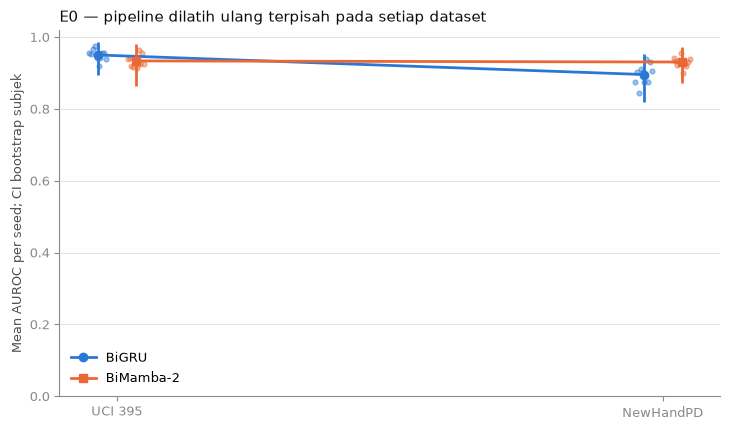

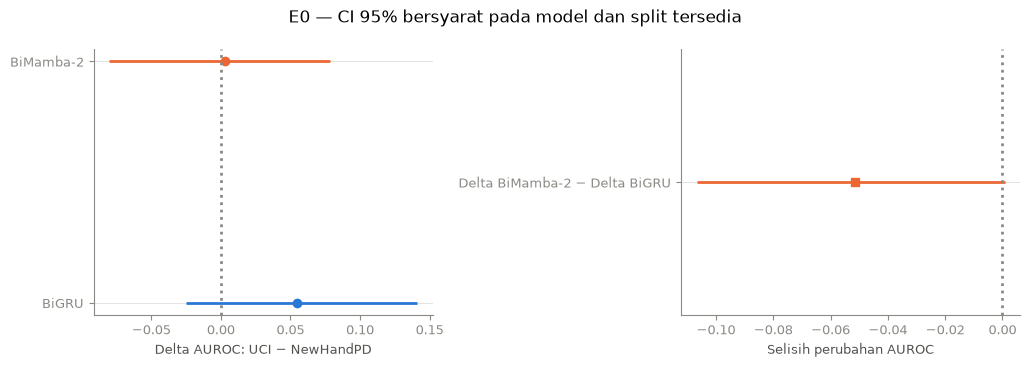

In [6]:
colors = {"gru": WARNA["biru"], "mamba2": WARNA["jingga"]}
labels = {"gru": "BiGRU", "mamba2": "BiMamba-2"}
fig, ax = plt.subplots(figsize=(7.4, 4.4))
for offset, arm in zip((-0.035, 0.035), ARMS):
    table = e0["cohort"].set_index(["architecture", "cohort"])
    rows = table.loc[arm].reindex(["uci395", "newhandpd"])
    x = np.arange(2) + offset
    ax.plot(x, rows.mean_auroc, marker="o" if arm == "gru" else "s",
            color=colors[arm], label=labels[arm])
    for xx, row in zip(x, rows.itertuples()):
        ax.vlines(xx, row.ci_low, row.ci_high, color=colors[arm], lw=2)
    for xx, cohort in zip(x, ("uci395", "newhandpd")):
        seed_values = per_seed.loc[(per_seed.architecture == arm) & (per_seed.cohort == cohort), "auroc"]
        ax.scatter(xx + np.linspace(-.015, .015, len(seed_values)), seed_values,
                   s=12, alpha=.45, color=colors[arm])
ax.set_xticks([0, 1], ["UCI 395", "NewHandPD"])
ax.set_ylim(0, 1.02)
ax.set_ylabel("Mean AUROC per seed; CI bootstrap subjek")
ax.set_title("E0 — pipeline dilatih ulang terpisah pada setiap dataset", loc="left")
ax.legend(); rapikan(ax); fig.tight_layout()
save_figure(fig, "e0_auroc_cohort"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.7))
for i, row in enumerate(e0["delta"].itertuples()):
    axes[0].hlines(i, row.ci_low, row.ci_high, color=colors[row.architecture], lw=2)
    axes[0].plot(row.delta_uci_minus_new, i, "o", color=colors[row.architecture])
axes[0].set_yticks(range(len(ARMS)), [labels[a] for a in ARMS])
axes[0].set_xlabel("Delta AUROC: UCI − NewHandPD")
row = e0["contrast"].iloc[0]
axes[1].hlines(0, row.ci_low, row.ci_high, color=WARNA["jingga"], lw=2)
axes[1].plot(row.contrast, 0, "s", color=WARNA["jingga"])
axes[1].set_yticks([0], ["Delta BiMamba-2 − Delta BiGRU"])
axes[1].set_xlabel("Selisih perubahan AUROC")
for ax in axes:
    ax.axvline(0, color=WARNA["netral"], linestyle=":"); rapikan(ax)
fig.suptitle("E0 — CI 95% bersyarat pada model dan split tersedia")
fig.tight_layout(); save_figure(fig, "e0_delta_contrast"); plt.show()

## 5. E1 — perubahan kontinu pada rekaman yang sama

Seluruh pasangan seed dipakai (10 seed menghasilkan 45 pasangan per rekaman).
Pasangan seed bukan 45 subjek baru. Tidak ada uji p-value dengan pasangan sebagai
observasi independen.

- `abs_delta_prob` dan `abs_delta_logit`: perubahan output individual utama.
- `js_divergence`: JSD base-2 antara distribusi α, dalam [0,1], bukan akar JSD.
- `rho_alpha` dan `(1-rho)/2`: kesamaan ranking dan perubahan ranking.
- `top_jaccard_fractional`: Jaccard top-10%, dengan massa fraksional bila tie
  melintasi batas k. Tanpa tie, identik dengan Jaccard himpunan top-k biasa.
  Ties dan peta uniform dicatat. Spearman peta uniform tetap NaN, tidak diganti 1.

Ringkasan utama: mean pasangan per rekaman → mean rekaman per subjek → mean subjek.
CI mengambil subjek, bukan patch/rekaman/pasangan. Asosiasi kontinu output–JSD
dihitung per rekaman, lalu diringkas per subjek; ia tidak menyatakan sebab-akibat.


In [7]:
pairs = e1_pairs(new, top_fraction=TOP_FRACTION)
record_continuous, subject_continuous = e1_subject_summary(pairs)
continuous_ci = bootstrap_subject_table(subject_continuous, E1_METRICS,
    n_boot=N_BOOT, random_seed=BOOT_SEED_E1, confidence=CONFIDENCE)
subject_relations = e1_subject_relations(pairs)
relation_ci = bootstrap_subject_table(subject_relations,
    ("rho_delta_prob_vs_jsd", "rho_delta_logit_vs_jsd"),
    n_boot=N_BOOT, random_seed=BOOT_SEED_E1, confidence=CONFIDENCE)
for filename, table in (
    ("e1_pairs.csv", pairs), ("e1_record_continuous.csv", record_continuous),
    ("e1_subject_continuous.csv", subject_continuous), ("e1_continuous_ci.csv", continuous_ci),
    ("e1_subject_relations.csv", subject_relations), ("e1_relation_ci.csv", relation_ci),
):
    save_table(table, filename)
display(continuous_ci)
display(relation_ci)
display(pairs.groupby("architecture").agg(n_pair_record=("idx", "size"),
    n_subjects=("subject", "nunique"), n_records=("idx", "nunique"),
    n_undefined_rho=("rho_alpha", lambda x: x.isna().sum()),
    n_uniform_a=("uniform_a", "sum"), n_uniform_b=("uniform_b", "sum")))

,architecture,metric,estimate,ci_low,ci_high,n_subjects_total,n_subjects_valid,n_pd_valid,n_hc_valid,n_boot_valid,n_boot_requested,status,unit,inference
0,gru,abs_delta_prob,0.192762,0.158517,0.226894,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
1,gru,abs_delta_logit,3.642454,3.243569,4.085562,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
2,gru,class_agreement,0.803283,0.766498,0.839985,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
3,gru,rho_alpha,0.146987,0.137853,0.156280,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
4,gru,rank_disagreement,0.426506,0.421860,0.431073,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
5,gru,js_divergence,0.773899,0.764830,0.782510,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
6,gru,top_jaccard_fractional,0.126939,0.120749,0.132921,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
7,mamba2,abs_delta_prob,0.160295,0.127418,0.194187,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
8,mamba2,abs_delta_logit,3.011433,2.593543,3.427288,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
9,mamba2,class_agreement,0.839141,0.803702,0.873232,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."


,architecture,metric,estimate,ci_low,ci_high,n_subjects_total,n_subjects_valid,n_pd_valid,n_hc_valid,n_boot_valid,n_boot_requested,status,unit,inference
0,gru,rho_delta_prob_vs_jsd,0.096011,0.069809,0.123240,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
1,gru,rho_delta_logit_vs_jsd,0.118517,0.094520,0.143657,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
2,mamba2,rho_delta_prob_vs_jsd,0.092883,0.056247,0.129176,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
3,mamba2,rho_delta_logit_vs_jsd,0.067258,0.031440,0.102749,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."


,n_pair_record,n_subjects,n_records,n_undefined_rho,n_uniform_a,n_uniform_b
architecture,,,,,,
gru,11880,66,264,0,0,0
mamba2,11880,66,264,0,0,0


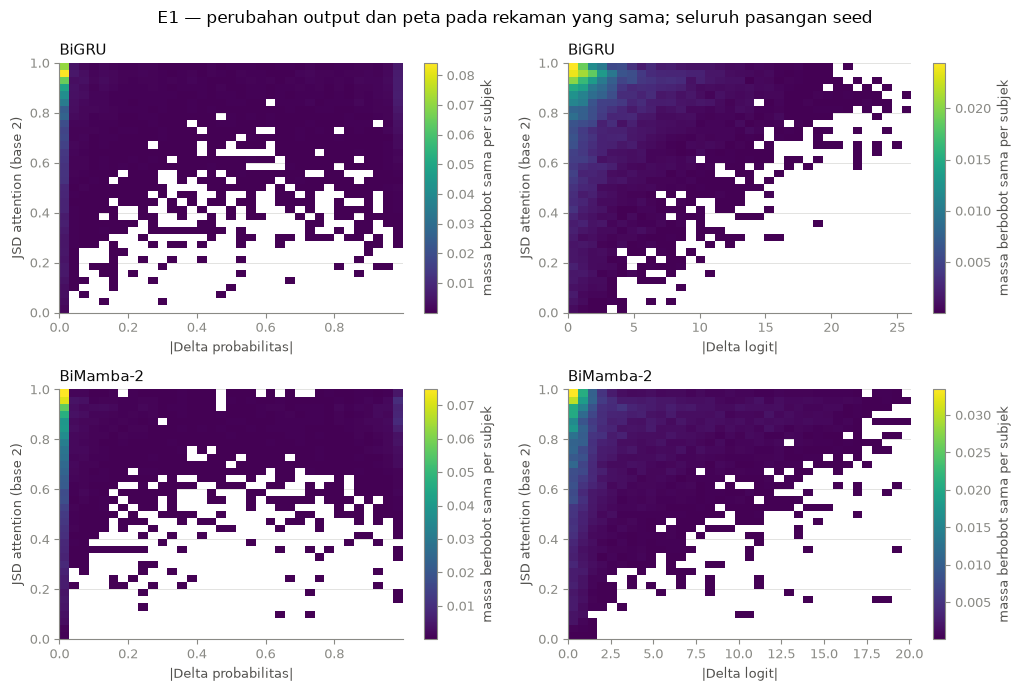

In [8]:
fig, axes = plt.subplots(len(ARMS), 2, figsize=(10.4, 7.0), squeeze=False)
for i, arm in enumerate(ARMS):
    d = pairs[pairs.architecture == arm].copy()
    # Massa total setiap subjek sama; bukan bobot independensi statistik.
    n_records = d.groupby("subject").idx.transform("nunique")
    n_pairs_record = d.groupby(["subject", "idx"]).idx.transform("size")
    weight = 1 / (d.subject.nunique() * n_records * n_pairs_record)
    for j, field in enumerate(("abs_delta_prob", "abs_delta_logit")):
        x = d[field].to_numpy()
        xmax = max(float(x.max()), 1e-8)
        histogram, xe, ye = np.histogram2d(x, d.js_divergence.to_numpy(), bins=35,
                                          range=[[0, xmax], [0, 1]], weights=weight)
        artist = axes[i, j].pcolormesh(xe, ye, np.ma.masked_where(histogram.T == 0, histogram.T),
                                      cmap="viridis", shading="auto", rasterized=True)
        fig.colorbar(artist, ax=axes[i, j], label="massa berbobot sama per subjek")
        axes[i, j].set_xlabel("|Delta probabilitas|" if j == 0 else "|Delta logit|")
        axes[i, j].set_ylabel("JSD attention (base 2)")
        axes[i, j].set_title(labels[arm], loc="left"); rapikan(axes[i, j])
fig.suptitle("E1 — perubahan output dan peta pada rekaman yang sama; seluruh pasangan seed")
fig.tight_layout(); save_figure(fig, "e1_continuous_output_map"); plt.show()

## 6. E1 — sensitivitas definisi output relatif stabil

Semua ambang probabilitas dikombinasikan dengan tanpa ambang logit dan tiga ambang
logit. Skenario logit saja serta semua pasangan juga disertakan. Skenario stabil
selalu mensyaratkan keputusan kelas sama. **Tidak ada ambang yang dijadikan keputusan
konfirmatori atau batas klinis.**

Filter diterapkan pada pasangan dalam rekaman yang sama. Mean metrik dihitung
atas pasangan eligible per rekaman, lalu rekaman eligible per subjek. Setiap
subjek berbobot sama dalam mean conditional. Subjek tanpa pasangan eligible tetap
ada dalam tabel/pool bootstrap dengan metrik NaN; cakupannya tidak disembunyikan.
`fraction_pairs_eligible` dan `fraction_records_eligible` diringkas atas seluruh
subjek. CI conditional dengan sedikit subjek atau sedikit draw valid harus dibaca
bersama kolom cakupan, bukan sebagai kesimpulan untuk seluruh kohort.


In [9]:
sensitivity_subject = e1_sensitivity(pairs, eps_prob=EPS_PROB, eps_logit=EPS_LOGIT)
sensitivity_ci = bootstrap_subject_table(sensitivity_subject,
    E1_METRICS + ("fraction_pairs_eligible", "fraction_records_eligible"),
    group_columns=("architecture", "scenario", "eps_prob", "eps_logit", "require_same_class"),
    n_boot=N_BOOT, random_seed=BOOT_SEED_E1, confidence=CONFIDENCE)
save_table(sensitivity_subject, "e1_sensitivity_subject.csv")
save_table(sensitivity_ci, "e1_sensitivity_ci.csv")
display(sensitivity_ci[sensitivity_ci.metric.isin(
    ["js_divergence", "top_jaccard_fractional", "fraction_pairs_eligible"])])
print("Periksa n_subjects_valid, n_pd_valid, n_hc_valid dan n_boot_valid untuk setiap ambang.")

,architecture,scenario,eps_prob,eps_logit,require_same_class,metric,estimate,ci_low,ci_high,n_subjects_total,n_subjects_valid,n_pd_valid,n_hc_valid,n_boot_valid,n_boot_requested,status,unit,inference
5,gru,all_pairs,NaN,NaN,False,js_divergence,0.773899,0.764830,0.782510,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
6,gru,all_pairs,NaN,NaN,False,top_jaccard_fractional,0.126939,0.120749,0.132921,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
7,gru,all_pairs,NaN,NaN,False,fraction_pairs_eligible,1.000000,1.000000,1.000000,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
14,gru,p<=0.01;logit<=0.1;same_class,0.01,0.10,True,js_divergence,0.725203,0.693633,0.755543,66,59,29,30,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
15,gru,p<=0.01;logit<=0.1;same_class,0.01,0.10,True,top_jaccard_fractional,0.146282,0.131608,0.161597,66,59,29,30,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,mamba2,p<=None;logit<=0.25;same_class,NaN,0.25,True,top_jaccard_fractional,0.140663,0.124115,0.157951,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
277,mamba2,p<=None;logit<=0.25;same_class,NaN,0.25,True,fraction_pairs_eligible,0.133418,0.112454,0.155642,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
284,mamba2,p<=None;logit<=0.5;same_class,NaN,0.50,True,js_divergence,0.741157,0.716945,0.765061,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
285,mamba2,p<=None;logit<=0.5;same_class,NaN,0.50,True,top_jaccard_fractional,0.139222,0.123495,0.155519,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."


Periksa n_subjects_valid, n_pd_valid, n_hc_valid dan n_boot_valid untuk setiap ambang.


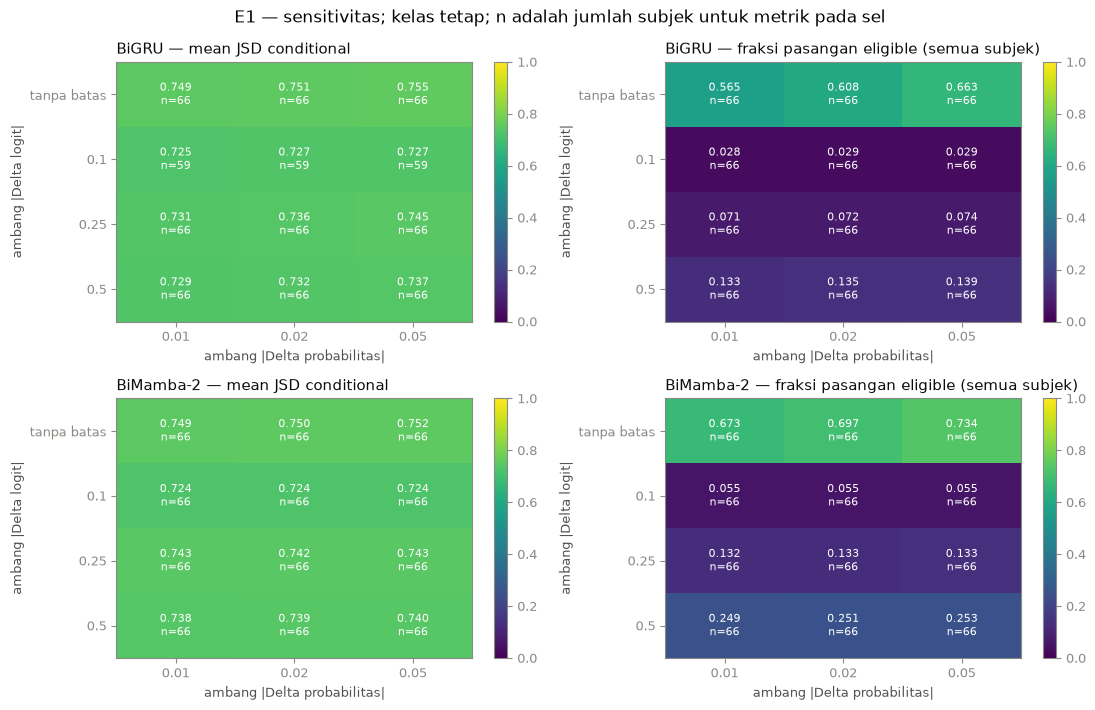

In [10]:
fig, axes = plt.subplots(len(ARMS), 2, figsize=(11.3, 7.2), squeeze=False)
for i, arm in enumerate(ARMS):
    for j, metric in enumerate(("js_divergence", "fraction_pairs_eligible")):
        values = np.full((len(EPS_LOGIT), len(EPS_PROB)), np.nan)
        coverage = np.zeros_like(values, dtype=int)
        for r, eps_l in enumerate(EPS_LOGIT):
            for c, eps_p in enumerate(EPS_PROB):
                d = sensitivity_ci[(sensitivity_ci.architecture == arm) &
                    (sensitivity_ci.metric == metric) & sensitivity_ci.require_same_class &
                    np.isclose(sensitivity_ci.eps_prob, eps_p)]
                d = d[d.eps_logit.isna()] if eps_l is None else d[np.isclose(d.eps_logit, eps_l)]
                if len(d) != 1:
                    raise ValueError("sel sensitivitas tidak unik")
                values[r, c] = d.estimate.iloc[0]
                coverage[r, c] = int(d.n_subjects_valid.iloc[0])
        artist = axes[i, j].imshow(np.ma.masked_invalid(values), vmin=0, vmax=1,
                                   cmap="viridis", aspect="auto")
        fig.colorbar(artist, ax=axes[i, j])
        for r in range(len(EPS_LOGIT)):
            for c in range(len(EPS_PROB)):
                text = f"{values[r,c]:.3f}\nn={coverage[r,c]}" if np.isfinite(values[r,c]) else "NA\nn=0"
                axes[i, j].text(c, r, text, ha="center", va="center", color="white", fontsize=8)
        axes[i, j].set_xticks(range(len(EPS_PROB)), [str(p) for p in EPS_PROB])
        axes[i, j].set_yticks(range(len(EPS_LOGIT)),
            ["tanpa batas" if v is None else str(v) for v in EPS_LOGIT])
        axes[i, j].set_xlabel("ambang |Delta probabilitas|")
        axes[i, j].set_ylabel("ambang |Delta logit|")
        title = "mean JSD conditional" if j == 0 else "fraksi pasangan eligible (semua subjek)"
        axes[i, j].set_title(f"{labels[arm]} — {title}", loc="left")
        axes[i, j].grid(False)
fig.suptitle("E1 — sensitivitas; kelas tetap; n adalah jumlah subjek untuk metrik pada sel")
fig.tight_layout(); save_figure(fig, "e1_sensitivity_coverage"); plt.show()

## 7. Batas interpretasi dan catatan penyelesaian

E0 menilai konsistensi performa **arsitektur/pipeline yang dilatih ulang** pada dua
dataset. CI bukan ketidakpastian atas semua kemungkinan training, split, atau kohort.
CI contrast yang mencakup nol bukan bukti ekuivalensi.

E1 mengukur perubahan attention, bukan kualitas penjelasan. Output stabil dan peta
berbeda dapat mencerminkan penjelasan yang tidak unik. Output stabil dan peta stabil
juga belum membuktikan faithfulness. Keduanya memerlukan intervensi input langsung E2.
E1 tidak menggunakan marker atau SHAP sebagai ground truth dan tidak membuat rasio
perubahan attention/AUROC. Semua ambang di sini merupakan sensitivitas tambahan.

Sebelum memilih E2/E3, bagikan manifest, laporan keselarasan, tabel E0 contrast,
ringkasan kontinu/asosiasi E1, dan tabel sensitivitas beserta cakupannya. Tidak ada
checkpoint yang dibuat atau dipulihkan oleh notebook ini.


In [11]:
# Pastikan input/sumber tidak berganti selama notebook berjalan.
inventory["sha256_after"] = [file_sha256(ROOT / p) for p in inventory.path]
inventory["unchanged"] = inventory.sha256_before == inventory.sha256_after
save_table(inventory, "input_inventory.csv")
if not inventory.unchanged.all():
    manifest["completion_status"] = "invalid_inputs_changed"
    (OUT / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    raise RuntimeError("input/sumber berubah selama analisis; jangan gunakan hasil run ini")
manifest["completion_status"] = "complete"
manifest["completed_utc"] = datetime.now(timezone.utc).isoformat()
manifest["tables"] = sorted(p.name for p in OUT.glob("*.csv"))
manifest["figures"] = sorted(p.name for p in FIG.iterdir())
(OUT / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
display(pd.DataFrame({"table": manifest["tables"]}))
print("Selesai:", OUT)
print("Grafik:", FIG)
print("Analisis tambahan; preregistrasi lama tetap. E1 tidak menyimpulkan faithfulness.")

,table
0,alignment_provenance.csv
1,e0_auroc_per_seed.csv
2,e0_cohort.csv
3,e0_contrast.csv
4,e0_delta.csv
5,e0_draws.csv
6,e0_probability_subject_seed.csv
7,e0_reference_check.csv
8,e1_continuous_ci.csv
9,e1_pairs.csv


Selesai: /home/agribychaniago/Python Projects/Skripsi/results/e0_e1/20261012T035813806939Z
Grafik: /home/agribychaniago/Python Projects/Skripsi/figures/e0_e1/20261012T035813806939Z
Analisis tambahan; preregistrasi lama tetap. E1 tidak menyimpulkan faithfulness.
